<a href="https://colab.research.google.com/github/mustansirrishi/DS4115-Marketing-Analytics/blob/main/0152330041_LAB2_DS4115.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")
print("Environment successfully set up!")

Environment successfully set up!


In [ ]:
# Set random seed for reproducibility
np.random.seed(42)
n_rows = 5000

# Generate dummy session attributes
session_ids = [f"sess_{i:04d}" for i in range(1, n_rows + 1)]
user_ids = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n_rows)]
device_categories = np.random.choice(['desktop', 'mobile', 'tablet'], size=n_rows, p=[0.5, 0.4, 0.1])

# Funnel flags (session_start is always 1, others follow realistic probabilities)
session_start_flag = np.ones(n_rows, dtype=int)
add_to_cart_flag = np.random.choice([0, 1], size=n_rows, p=[0.7, 0.3])  # ~30% add to cart
purchase_flag = np.where(add_to_cart_flag == 1, np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6]), 0)  # ~60% conversion from cart

page_views = np.random.poisson(lam=3, size=n_rows) + 1
time_on_site_sec = page_views * np.random.randint(20, 60, size=n_rows)

# Create DataFrame
df = pd.DataFrame({
    'session_id': session_ids,
    'user_id': user_ids,
    'device_category': device_categories,
    'session_start_flag': session_start_flag,
    'add_to_cart_flag': add_to_cart_flag,
    'purchase_flag': purchase_flag,
    'page_views': page_views,
    'time_on_site_sec': time_on_site_sec
})

# Introduce artificial missing values in 'time_on_site_sec' for data cleaning practice
df.loc[np.random.choice(n_rows, 50), 'time_on_site_sec'] = np.nan

# Save to CSV and inspect the first 5 rows
df.to_csv('ga4_sample_session_logs.csv', index=False)
print("Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!")
df.head()

Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!


,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,tablet,1,0,0,5,155.0
1,sess_0002,user_1435,desktop,1,0,0,3,171.0
2,sess_0003,user_1860,tablet,1,0,0,2,110.0
3,sess_0004,user_1270,desktop,1,0,0,4,140.0
4,sess_0005,user_1106,desktop,1,1,0,4,80.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          5000 non-null   object 
 1   user_id             5000 non-null   object 
 2   device_category     5000 non-null   object 
 3   session_start_flag  5000 non-null   int64  
 4   add_to_cart_flag    5000 non-null   int64  
 5   purchase_flag       5000 non-null   int64  
 6   page_views          5000 non-null   int64  
 7   time_on_site_sec    4950 non-null   float64
dtypes: float64(1), int64(4), object(3)
memory usage: 312.6+ KB


In [ ]:
# Calculate funnel metrics
total_sessions = df['session_id'].nunique()
sessions_with_cart = df[df['add_to_cart_flag'] == 1]['session_id'].nunique()
sessions_with_purchase = df[df['purchase_flag'] == 1]['session_id'].nunique()

# Create a summary DataFrame
funnel_data = {
    'Funnel Step': ['1. Session Start', '2. Add to Cart', '3. Purchase'],
    'User Sessions': [total_sessions, sessions_with_cart, sessions_with_purchase]
}
funnel_df = pd.DataFrame(funnel_data)

# Calculate conversion rates relative to step 1
funnel_df['Conversion Rate (%)'] = (funnel_df['User Sessions'] / total_sessions) * 100

# Optional: Add step-to-step conversion and drop-off rates for deeper analysis
funnel_df['Step-to-Step Conv. (%)'] = funnel_df['User Sessions'].pct_change().add(1).fillna(1.0) * 100
funnel_df['Step Drop-Off (%)'] = 100 - funnel_df['Step-to-Step Conv. (%)']

print(funnel_df)

        Funnel Step  User Sessions  Conversion Rate (%)  \
0  1. Session Start           5000                100.0   
1    2. Add to Cart           1470                 29.4   
2       3. Purchase            905                 18.1   

   Step-to-Step Conv. (%)  Step Drop-Off (%)  
0              100.000000           0.000000  
1               29.400000          70.600000  
2               61.564626          38.435374  


In [ ]:
print(df.isnull().sum())

session_id             0
user_id                0
device_category        0
session_start_flag     0
add_to_cart_flag       0
purchase_flag          0
page_views             0
time_on_site_sec      50
dtype: int64


In [ ]:
# Impute missing time_on_site_sec with median
median_time = df['time_on_site_sec'].median()
print(f"Median time_on_site_sec used for imputation: {median_time} seconds")
df['time_on_site_sec'] = df['time_on_site_sec'].fillna(median_time)

# Drop rows with missing session IDs if any
df = df.dropna(subset=['session_id'])

# Clean categorical formatting
df['device_category'] = df['device_category'].str.lower().str.strip()
print("Data cleaning completed. Missing values remaining:", df.isnull().sum().sum())

Median time_on_site_sec used for imputation: 144.0 seconds
Data cleaning completed. Missing values remaining: 0


In [ ]:
# Select numerical columns relevant to conversion behavior
numeric_cols = ['session_start_flag', 'add_to_cart_flag', 'purchase_flag', 'page_views', 'time_on_site_sec']
corr_matrix = df[numeric_cols].corr()
print(corr_matrix)

                    session_start_flag  add_to_cart_flag  purchase_flag  \
session_start_flag                 NaN               NaN            NaN   
add_to_cart_flag                   NaN          1.000000       0.728494   
purchase_flag                      NaN          0.728494       1.000000   
page_views                         NaN         -0.010963      -0.000583   
time_on_site_sec                   NaN          0.001849       0.004230   

                    page_views  time_on_site_sec  
session_start_flag         NaN               NaN  
add_to_cart_flag     -0.010963          0.001849  
purchase_flag        -0.000583          0.004230  
page_views            1.000000          0.804072  
time_on_site_sec      0.804072          1.000000  


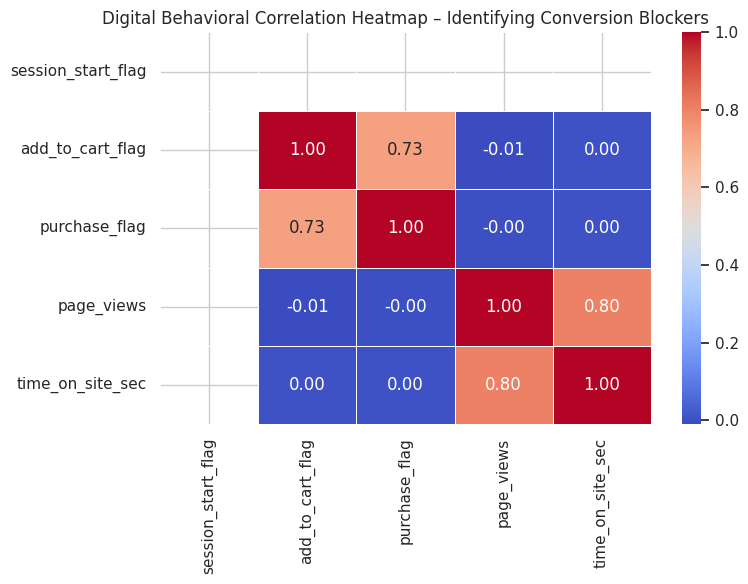

In [ ]:
# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Digital Behavioral Correlation Heatmap – Identifying Conversion Blockers", fontsize=12)
plt.tight_layout()
plt.show()

# VISUAL CONVERTION FUNNEL


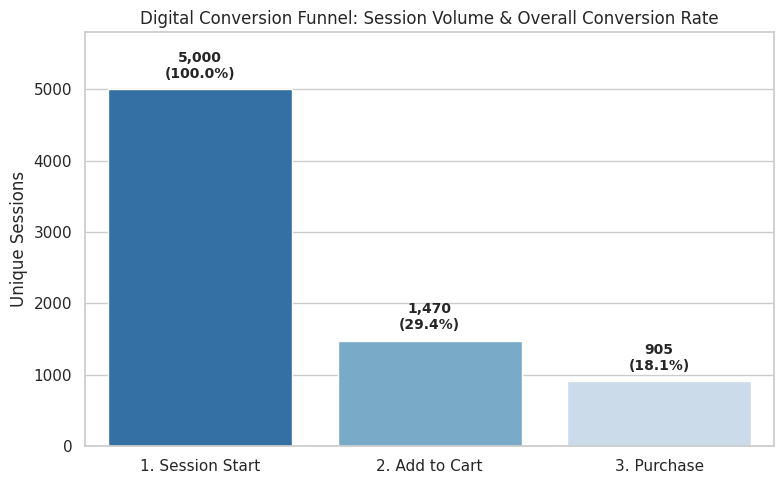

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=funnel_df,
    x='Funnel Step',
    y='User Sessions',
    hue='Funnel Step',
    dodge=False,
    palette='Blues_r'
)
if ax.get_legend():
    ax.get_legend().remove()

# Annotate each bar with session count and overall conversion rate
for i, row in funnel_df.iterrows():
    ax.text(
        i,
        row['User Sessions'] + 120,
        f"{row['User Sessions']:,}\n({row['Conversion Rate (%)']:.1f}%)",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=10
    )

ax.set_ylim(0, 5800)
ax.set_title("Digital Conversion Funnel: Session Volume & Overall Conversion Rate", fontsize=12)
ax.set_ylabel("Unique Sessions")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

#Funnel Conversion Rates by Device Category

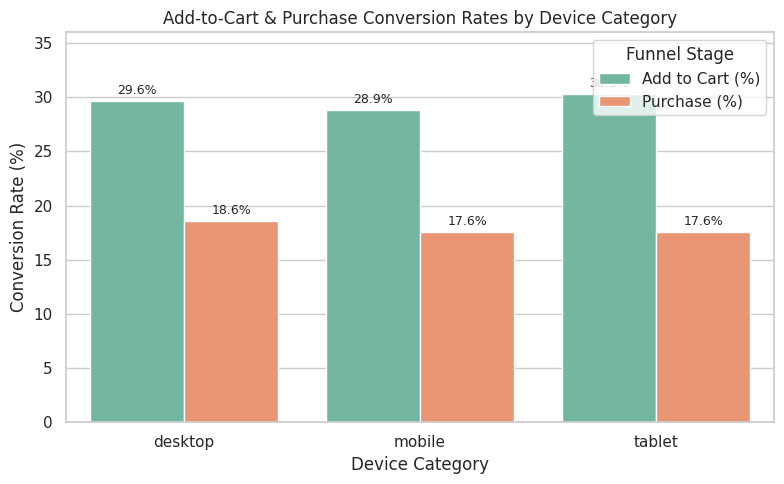

In [ ]:
# Aggregate conversion rates by device
device_rates = df.groupby('device_category')[['add_to_cart_flag', 'purchase_flag']].mean().reset_index()
device_melted = device_rates.melt(id_vars='device_category', var_name='Funnel Stage', value_name='Rate')
device_melted['Rate (%)'] = device_melted['Rate'] * 100
device_melted['Funnel Stage'] = device_melted['Funnel Stage'].map({
    'add_to_cart_flag': 'Add to Cart (%)',
    'purchase_flag': 'Purchase (%)'
})

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=device_melted,
    x='device_category',
    y='Rate (%)',
    hue='Funnel Stage',
    palette='Set2'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

ax.set_ylim(0, 36)
ax.set_title("Add-to-Cart & Purchase Conversion Rates by Device Category", fontsize=12)
ax.set_xlabel("Device Category")
ax.set_ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()

#Time on Site Distribution by Device & Purchase Outcome

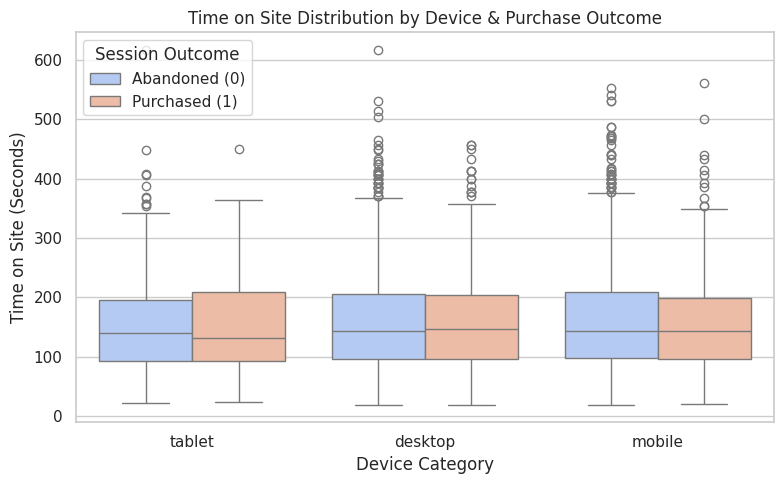

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=df,
    x='device_category',
    y='time_on_site_sec',
    hue='purchase_flag',
    palette='coolwarm'
)

ax.set_title("Time on Site Distribution by Device & Purchase Outcome", fontsize=12)
ax.set_xlabel("Device Category")
ax.set_ylabel("Time on Site (Seconds)")

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Abandoned (0)', 'Purchased (1)'], title='Session Outcome')
plt.tight_layout()
plt.show()

#Engagement Depth vs. Purchase Outcome

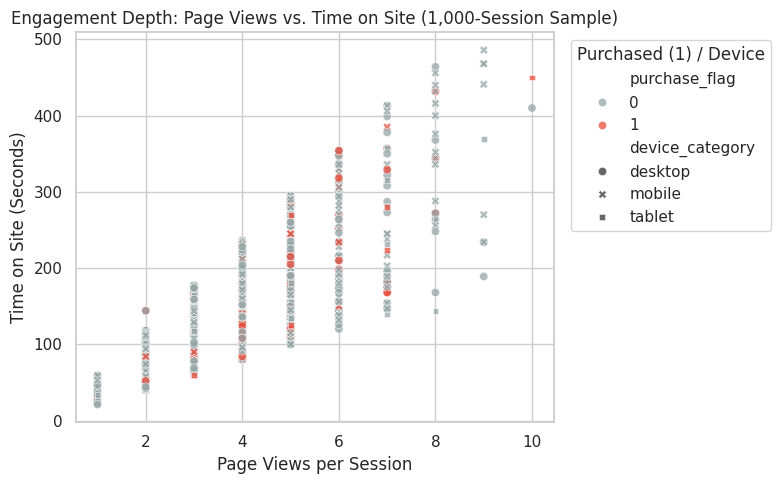

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.sample(1000, random_state=42),  # Sample 1,000 points for visual clarity
    x='page_views',
    y='time_on_site_sec',
    hue='purchase_flag',
    style='device_category',
    palette={0: '#95a5a6', 1: '#e74c3c'},
    alpha=0.75
)

plt.title("Engagement Depth: Page Views vs. Time on Site (1,000-Session Sample)", fontsize=12)
plt.xlabel("Page Views per Session")
plt.ylabel("Time on Site (Seconds)")
plt.legend(title="Purchased (1) / Device", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()